# PV-relative centreline composites
Figure 17. Settings: `composites.json`. Deep planetary, magnitude-defined mixed and shallow topographic days; actual fitted centres within 0–1000 m.

Final PNGs: `../figures/`. Tables, reports and manifests: `outputs/`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import Markdown, display

HERE = Path.cwd().resolve()
if (HERE / "composites" / "composites.py").is_file():
    HERE = HERE / "composites"
elif not (HERE / "composites.py").is_file():
    HERE = HERE / "seacofs_eddy_tilt_analysis" / "manuscript" / "composites"
sys.path.insert(0, str(HERE))
import composites
CONFIG = HERE / "composites.json"

In [2]:
results = composites.run(CONFIG)
import matplotlib.pyplot as plt
plt.close("all")

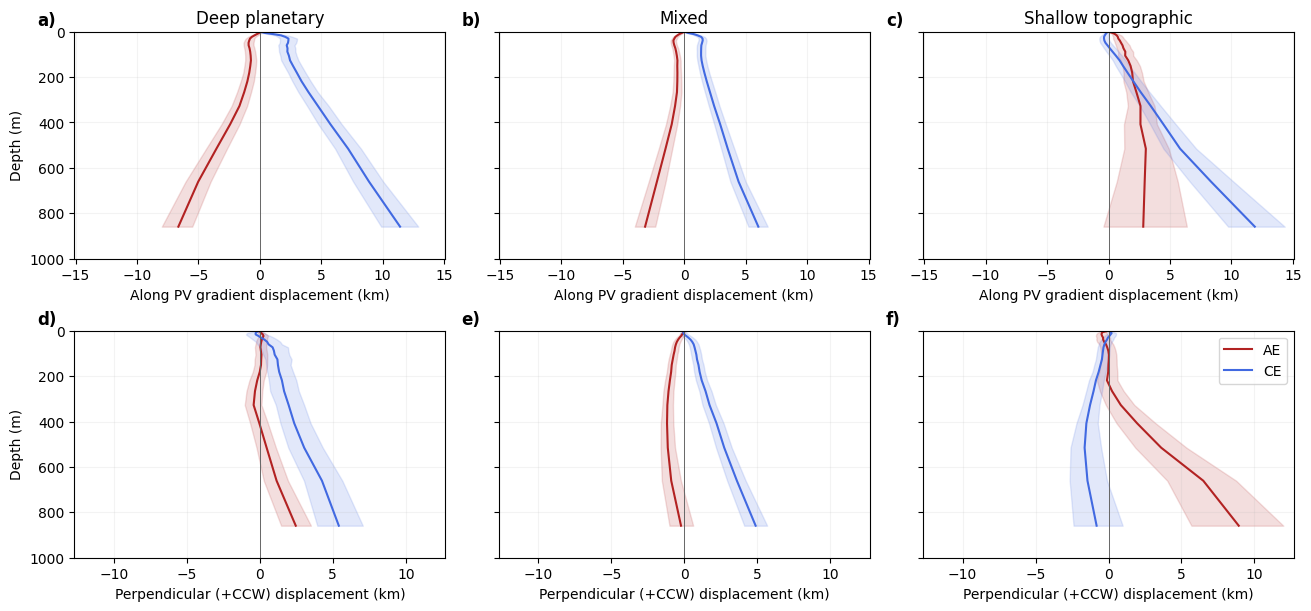

In [3]:
display(results["figure"])

In [4]:
display(Markdown((results["output_dir"] / "report.md").read_text()))
display(results["inventory"])

# PV-relative centreline composites

Figure 17: original six-panel layout and AE-red/CE-blue curves. Columns are deep planetary (h≥3000 m), magnitude-defined mixed (all depths), and shallow topographic (h≤3000 m). Dominance uses unsmoothed component magnitudes with factor 2; excluded other-depth dominated days are not mixed. h is Gaussian-footprint-mean water depth, separate from fitted profile depth.

Day selection uses saved tilt ≥5 km and the shared valid tilt/PV direction requirements. Use actual fitted levels within 0–1000 m, including surface, with a valid surface fit. No interpolation, extrapolation or velocity reconstruction. Existing profile QC requires finite centres/ESP parameters, positive radius and positive-definite ellipse matrices.

Each day is referenced to its own fitted surface centre and rotated into the local total environmental-PV frame before averaging: positive along is with the signed gradient; positive perpendicular is 90° counterclockwise. These are surface-to-depth constituent-centre displacements, not the saved deep-to-shallow fitted tilt vector.

Each available eddy-day has equal weight at each depth. Pointwise 95% confidence intervals resample whole eddy tracks (500 draws, seed 731); the same track draw is reused across depths within a regime/polarity. Bands quantify uncertainty in the mean, not population spread or fit-parameter uncertainty. Support can change with depth. These are descriptive composites, not a causal test.

Included profiles:

- AE planetary: 4,449 days / 510 eddies; deepest contributing fit 858.92 m.
- CE planetary: 1,874 days / 397 eddies; deepest contributing fit 858.92 m.
- AE mixed: 15,304 days / 969 eddies; deepest contributing fit 858.92 m.
- CE mixed: 9,984 days / 925 eddies; deepest contributing fit 858.92 m.
- AE topographic: 5,574 days / 346 eddies; deepest contributing fit 858.92 m.
- CE topographic: 8,855 days / 615 eddies; deepest contributing fit 858.92 m.

Deepest supported displayed points (mean along, perpendicular; pointwise 95% CI, km):

- AE mixed, 858.92 m: along -3.18 [-4.02, -2.36], perpendicular -0.22 [-1.01, 0.62]; 12,787 days / 868 eddies.
- CE mixed, 858.92 m: along 6.03 [5.23, 6.80], perpendicular 4.90 [4.12, 5.69]; 8,705 days / 851 eddies.
- AE planetary, 858.92 m: along -6.63 [-7.98, -5.51], perpendicular 2.46 [1.46, 3.50]; 4,053 days / 433 eddies.
- CE planetary, 858.92 m: along 11.41 [9.88, 12.89], perpendicular 5.41 [3.94, 7.05]; 1,713 days / 365 eddies.
- AE topographic, 858.92 m: along 2.82 [-0.42, 6.37], perpendicular 8.92 [5.68, 11.98]; 3,332 days / 270 eddies.
- CE topographic, 858.92 m: along 11.90 [9.74, 14.34], perpendicular -0.82 [-2.40, 0.97]; 6,503 days / 554 eddies.

Curves require ≥2 eddies; open symbols flag fewer than 20. Track counts across regimes overlap and must not be summed as distinct eddies. Missing levels contribute no artificial zero or extra depth coverage. The plot axis extends to the configured cap; curves stop at actual data.

Writing tables: centre_statistics.csv (means, CI, covariance/spread and depth support), inventory.csv, exclusions.csv; day_audit.csv records both dominance and depth selection. members.parquet preserves projected constituent centres. manifest.json records source, config/product/code identities and grid rotation. No original source or PV cache was rebuilt.


,regime,Cyc,eddy_days,eddies,deepest_contributing_m
0,planetary,AE,4449,510,858.918478
1,planetary,CE,1874,397,858.918478
2,mixed,AE,15304,969,858.918478
3,mixed,CE,9984,925,858.918478
4,topographic,AE,5574,346,858.918478
5,topographic,CE,8855,615,858.918478
